# Prediksi Risiko Stroke Berdasarkan Indikator Medis dan Gaya Hidup

## 1. Business & Data Understanding
### 1.1 Latar Belakang & Tujuan
Stroke merupakan penyebab utama kematian dan disabilitas jangka panjang. Deteksi dini risiko stroke berdasarkan indikator klinis dan gaya hidup diperlukan untuk membantu fasilitas kesehatan melakukan penapisan (*screening*) preventif. Tujuan proyek ini adalah membangun model klasifikasi untuk memprediksi risiko stroke pada pasien dengan memaksimalkan sensitivitas deteksi (*Recall*) agar meminimalkan kasus berisiko yang terlewat (*False Negative*).

### 1.2 Sumber Data & Lisensi
* **Nama Dataset**: Stroke Prediction Dataset (`healthcare-dataset-stroke-data.csv`)
* **Sumber**: Kaggle (diunggah oleh *fedesoriano*)
* **Lisensi**: Data Publik (CC0 / Public Domain) untuk keperluan riset dan edukasi.
* **Dimensi**: 5.110 baris dan 12 kolom.

### 1.3 Data Dictionary
| Nama Variabel | Tipe Data | Satuan / Kategori | Keterangan |
| :--- | :--- | :--- | :--- |
| `id` | Numerik (int) | ID Unik | Nomor identitas pasien (non-prediktif) |
| `gender` | Kategorikal | Male, Female, Other | Jenis kelamin pasien |
| `age` | Numerik (float) | Tahun | Usia pasien (rentang 0.08 – 82 tahun) |
| `hypertension` | Biner (int) | 0 = Tidak, 1 = Ya | Riwayat tekanan darah tinggi |
| `heart_disease` | Biner (int) | 0 = Tidak, 1 = Ya | Riwayat penyakit jantung |
| `ever_married` | Kategorikal | Yes, No | Status pernikahan |
| `work_type` | Kategorikal | Private, Self-employed, Govt_job, children, Never_worked | Jenis pekerjaan |
| `Residence_type` | Kategorikal | Urban, Rural | Tipe wilayah tempat tinggal |
| `avg_glucose_level` | Numerik (float) | mg/dL | Rata-rata kadar glukosa dalam darah |
| `bmi` | Numerik (float) | kg/m² | Indeks Massa Tubuh (*Body Mass Index*) |
| `smoking_status` | Kategorikal | formerly smoked, never smoked, smokes, Unknown | Status merokok pasien |
| `stroke` | Biner (Target) | 0 = Tidak Stroke, 1 = Stroke | Status riwayat stroke pasien |

### 1.4 Representativitas & Bias Sampel
1. **Ketidakseimbangan Kelas (*Class Imbalance*)**: Hanya **4,87%** (249 dari 5.110 pasien) yang berstatus `stroke = 1`, sedangkan **95,13%** (4.861 pasien) berstatus `stroke = 0`.
2. **Bias Pencatatan (*Missingness Bias*)**: Nilai `bmi` kosong sebanyak 201 baris (3,93%), tetapi proporsi kekosongan pada pasien stroke mencapai **16,06%** (jauh lebih tinggi dibanding non-stroke yang hanya **3,31%**). Hal ini mengindikasikan kondisi darurat medis membuat pengukuran berat/tinggi badan sering terlewat saat pasien masuk rumah sakit.
3. **Kategori `Unknown` pada Riwayat Merokok**: Sebanyak 1.544 pasien (30,2%) memiliki status merokok `Unknown` (didominasi kelompok usia anak-anak atau pasien yang tidak terdata riwayatnya).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Library Preprocessing & Feature Selection (Standard Scikit-Learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")

# Memuat dataset
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print(f"Dimensi Dataset Awal: {df.shape[0]} baris, {df.shape[1]} kolom")
display(df.head())

Dimensi Dataset Awal: 5110 baris, 12 kolom


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Audit Kualitas Data & Statistik Deskriptif
Tahap ini memeriksa tipe data, statistik deskriptif, duplikasi baris, *missing values*, dan deteksi *outlier* menggunakan metode Interquartile Range (IQR) sebelum dilakukan pembersihan data.

In [2]:
# 1. Informasi struktur tipe data
print("=== Informasi Tipe Data ===")
df.info()

# 2. Statistik Deskriptif
print("\n=== Statistik Deskriptif Fitur Numerik ===")
display(df.describe().T)

print("\n=== Statistik Deskriptif Fitur Kategorikal ===")
display(df.describe(include='object').T)

# 3. Audit Duplikasi & Missing Values
print(f"\nJumlah Baris Duplikat: {df.duplicated().sum()}")

missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df)) * 100
})
print("\n=== Audit Missing Values ===")
display(missing_df[missing_df['Missing Count'] > 0])

# Cek proporsi missing BMI berdasarkan status stroke
print("=== Proporsi Missing BMI per Kelas Target ===")
display(df.groupby('stroke')['bmi'].apply(lambda x: f"{x.isnull().sum()} ({x.isnull().mean()*100:.2f}%)"))

# 4. Audit Outlier dengan Metode IQR
num_features = ['age', 'avg_glucose_level', 'bmi']
outlier_summary = []

for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_summary.append({
        'Fitur': col,
        'Batas Bawah': round(lower_bound, 2),
        'Batas Atas': round(upper_bound, 2),
        'Jumlah Outlier': len(outliers),
        'Persentase (%)': round(len(outliers) / len(df) * 100, 2)
    })

print("\n=== Audit Outlier (Metode IQR) ===")
display(pd.DataFrame(outlier_summary))

# 5. Cek kategori minoritas/anomali pada fitur kategorikal
print("\n=== Distribusi Kategori Gender ===")
print(df['gender'].value_counts())

=== Informasi Tipe Data ===
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB

=== Statistik Deskriptif Fitur Numerik ===


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00



=== Statistik Deskriptif Fitur Kategorikal ===


C:\Users\aditz\AppData\Local\Temp\ipykernel_23100\216984362.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object').T)


,count,unique,top,freq
gender,5110,3,Female,2994
ever_married,5110,2,Yes,3353
work_type,5110,5,Private,2925
Residence_type,5110,2,Urban,2596
smoking_status,5110,4,never smoked,1892



Jumlah Baris Duplikat: 0

=== Audit Missing Values ===


... (2 outputs left out)

stroke
0    161 (3.31%)
1    40 (16.06%)
Name: bmi, dtype: str


=== Audit Outlier (Metode IQR) ===


,Fitur,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,age,-29.00,115.00,0,0.00
1,avg_glucose_level,21.98,169.36,627,12.27
2,bmi,9.10,47.50,110,2.15



=== Distribusi Kategori Gender ===
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA) & Visualisasi
Visualisasi dilakukan untuk memahami distribusi target, perbedaan karakteristik klinis antara pasien stroke dan non-stroke, serta hubungan korelasi antar variabel.

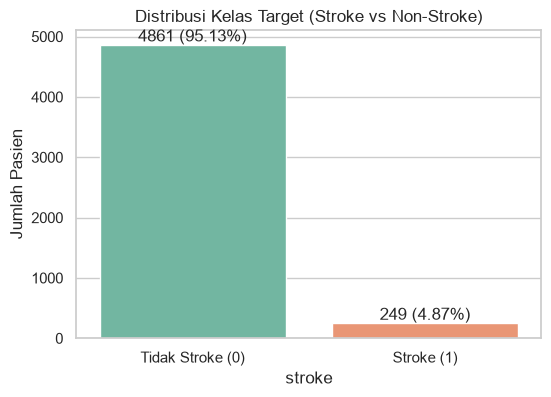

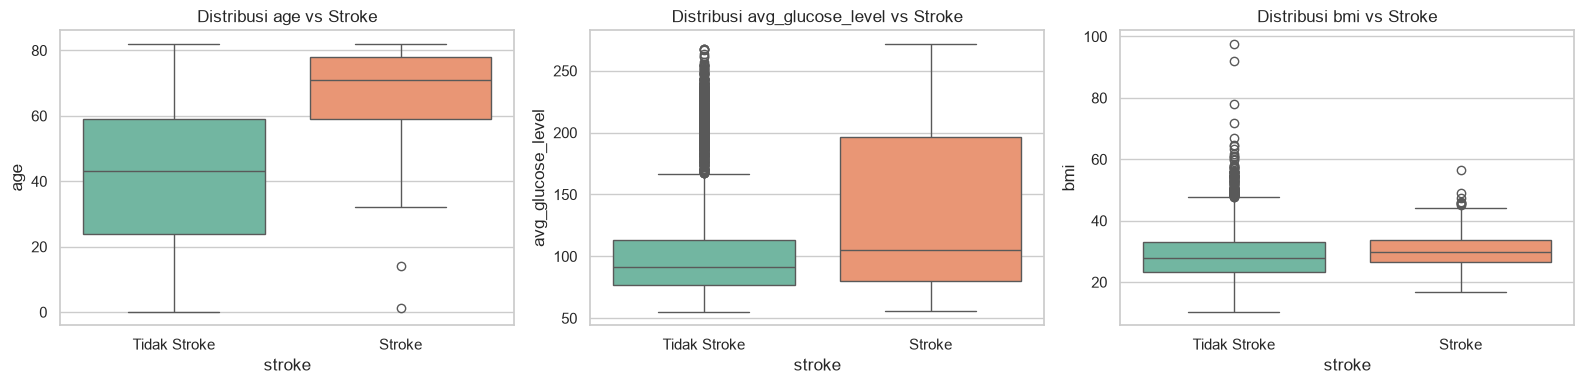

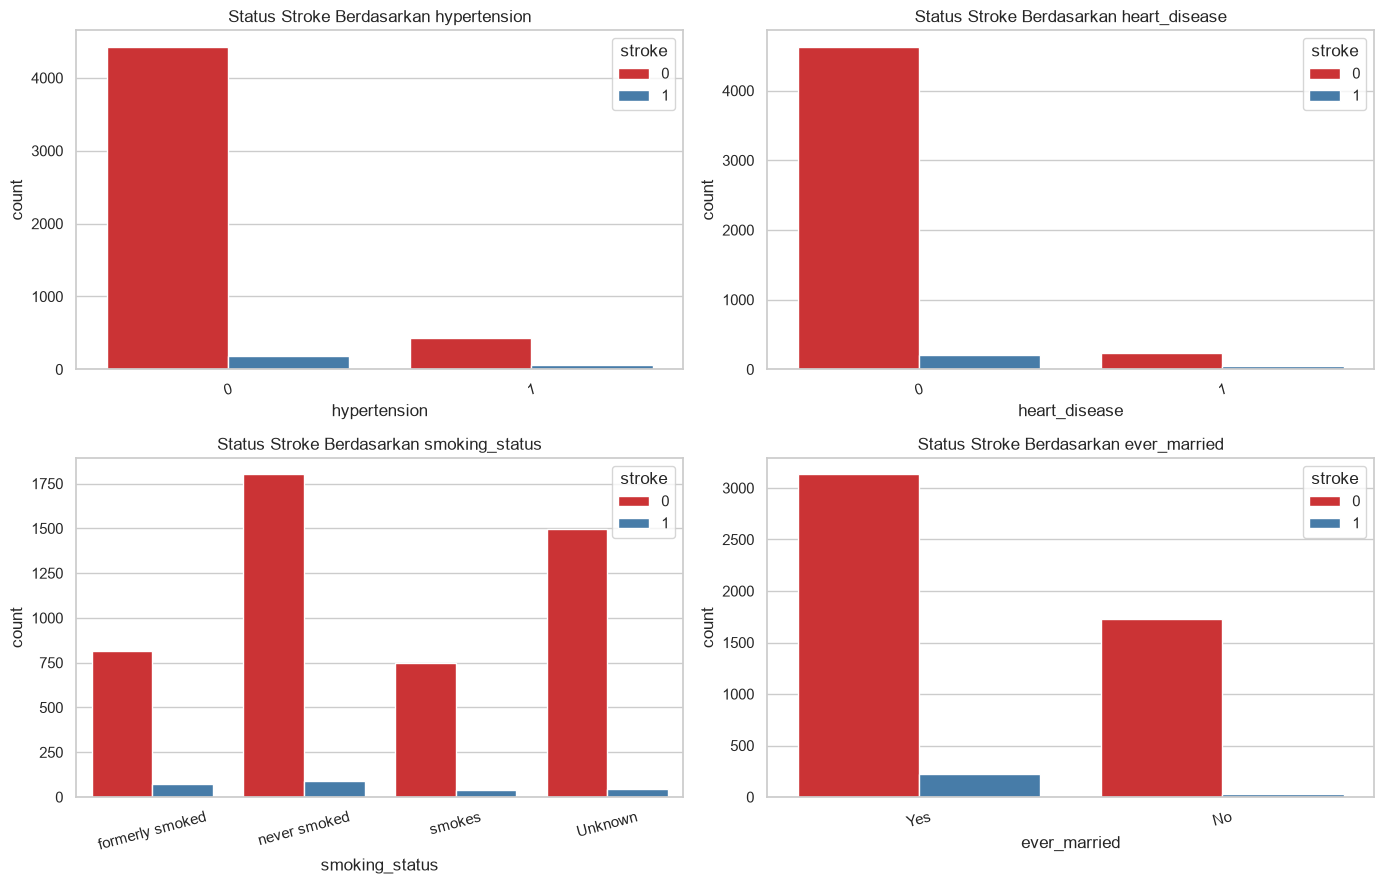

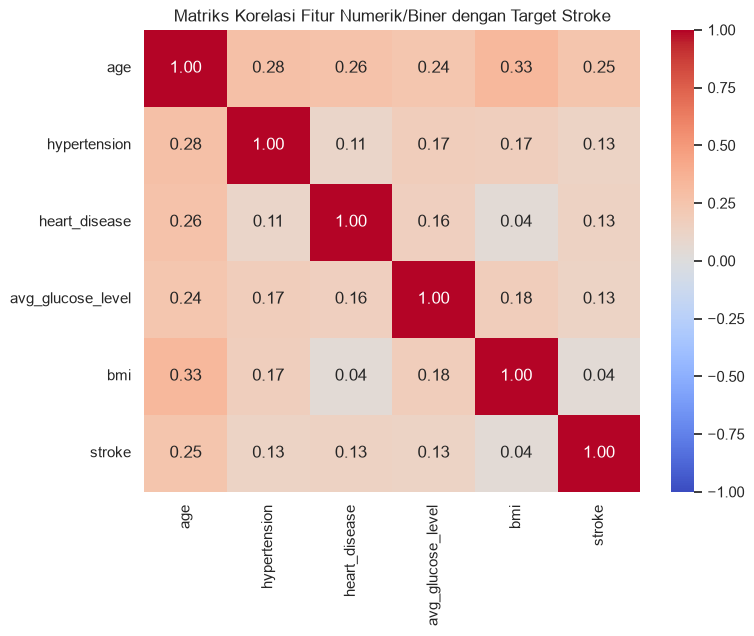

In [3]:
# 1. Visualisasi Distribusi Kelas Target (Imbalance)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='stroke', hue='stroke', palette='Set2', legend=False)
plt.title('Distribusi Kelas Target (Stroke vs Non-Stroke)')
plt.xticks([0, 1], ['Tidak Stroke (0)', 'Stroke (1)'])
plt.ylabel('Jumlah Pasien')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.2f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')
plt.show()

# 2. Boxplot Fitur Numerik vs Status Stroke
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for idx, col in enumerate(num_features):
    sns.boxplot(data=df, x='stroke', y=col, hue='stroke', ax=axes[idx], palette='Set2', legend=False)
    axes[idx].set_title(f'Distribusi {col} vs Stroke')
    axes[idx].set_xticks([0, 1])
    axes[idx].set_xticklabels(['Tidak Stroke', 'Stroke'])
plt.tight_layout()
plt.show()

# 3. Proporsi Stroke pada Fitur Kategorikal & Biner Utama
cat_key = ['hypertension', 'heart_disease', 'smoking_status', 'ever_married']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
for idx, col in enumerate(cat_key):
    sns.countplot(data=df, x=col, hue='stroke', ax=axes[idx], palette='Set1')
    axes[idx].set_title(f'Status Stroke Berdasarkan {col}')
    axes[idx].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

# 4. Heatmap Korelasi Antar Fitur Numerik/Biner dan Target
plt.figure(figsize=(8, 6))
corr_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriks Korelasi Fitur Numerik/Biner dengan Target Stroke')
plt.show()

### 3.1 Kesimpulan & Insight Utama EDA
1. **Insight 1  Missing Value `bmi` Terkonsentrasi pada Pasien Stroke (Keputusan Imputasi Median)**:
   * Nilai `bmi` yang hilang mencapai 16,06% pada pasien stroke dibanding 3,31% pada non-stroke, dan distribusinya menceng ke kanan (*right-skewed*). Baris kosong **tidak boleh dihapus** agar sampel kelas minoritas (`stroke = 1`) tidak berkurang drastis. Strategi yang dipilih adalah **imputasi menggunakan Median** karena tahan terhadap nilai ekstrem.
2. **Insight 2 Outlier Klinis pada Glukosa & BMI Bersifat Valid (Keputusan Retensi Outlier)**:
   * Ditemukan 12,27% *outlier* pada `avg_glucose_level` dan 2,15% pada `bmi`. Secara medis, kadar glukosa tinggi (>200 mg/dL) merepresentasikan kondisi diabetes yang merupakan faktor risiko nyata penyakit stroke, bukan kesalahan pencatatan. Oleh karena itu, *outlier* numerik **dipertahankan** dan akan ditangani skalanya menggunakan `StandardScaler`. Satu-satunya data yang dihapus adalah 1 baris `gender == 'Other'` (0,02%) karena tidak representatif secara statistik.
3. **Insight 3 Dominasi Faktor Usia & Ketimpangan Kelas (Keputusan Stratified Split & Class Weight)**:
   * Korelasi positif tertinggi terhadap `stroke` ditunjukkan oleh `age` ($r = 0,25$; median usia pasien stroke **71 tahun** vs non-stroke **43 tahun**), diikuti `heart_disease` ($r = 0,13$), `avg_glucose_level` ($r = 0,13$), dan `hypertension` ($r = 0,13$). Karena rasio kelas sangat timpang (95,13% vs 4,87%), pembagian data wajib menggunakan **`stratify=y`** agar proporsi kelas terjaga, serta penanganan ketimpangan kelas dilakukan melalui penyesuaian bobot kelas (**`class_weight='balanced'`**) dan **Random Oversampling** bawaan `pandas`/`sklearn` tanpa menambah data sintetis buatan.

## 4. Data Cleaning (Perbandingan Sebelum vs Sesudah)
Pada tahap ini dilakukan pembersihan awal:
1. Menghapus kolom `id` karena hanya merupakan identitas acak pasien.
2. Menghapus 1 baris dengan kategori `gender == 'Other'` agar variabel gender konsisten biner (`Male` / `Female`).
3. Menangani *missing values* pada `bmi` (imputasi median akan diterapkan di dalam *pipeline* setelah *splitting* untuk mencegah *data leakage*, namun di bawah ini ditampilkan simulasi hasil pembersihan secara keseluruhan sebagai verifikasi kualitas data).

In [4]:
# Simpan ringkasan sebelum cleaning
before_summary = {
    'Jumlah Baris': df.shape[0],
    'Jumlah Kolom': df.shape[1],
    'Missing Values (bmi)': df['bmi'].isnull().sum(),
    'Jumlah Duplikat': df.duplicated().sum(),
    'Kategori Gender': str(df['gender'].value_counts().to_dict())
}

# Proses Cleaning struktural
df_clean = df.drop(columns=['id']).copy()
df_clean = df_clean[df_clean['gender'] != 'Other'].reset_index(drop=True)

# Verifikasi hasil imputasi median (untuk perbandingan before-after)
df_after_check = df_clean.copy()
median_bmi_val = df_after_check['bmi'].median()
df_after_check['bmi'] = df_after_check['bmi'].fillna(median_bmi_val)

after_summary = {
    'Jumlah Baris': df_after_check.shape[0],
    'Jumlah Kolom': df_after_check.shape[1],
    'Missing Values (bmi)': df_after_check['bmi'].isnull().sum(),
    'Jumlah Duplikat': df_after_check.duplicated().sum(),
    'Kategori Gender': str(df_after_check['gender'].value_counts().to_dict())
}

comparison_df = pd.DataFrame({'Sebelum Cleaning': before_summary, 'Sesudah Cleaning': after_summary})
print("=== Perbandingan Kondisi Dataset Sebelum vs Sesudah Cleaning ===")
display(comparison_df)

=== Perbandingan Kondisi Dataset Sebelum vs Sesudah Cleaning ===


,Sebelum Cleaning,Sesudah Cleaning
Jumlah Baris,5110,5109
Jumlah Kolom,12,11
Missing Values (bmi),201,0
Jumlah Duplikat,0,0
Kategori Gender,"{'Female': 2994, 'Male': 2115, 'Other': 1}","{'Female': 2994, 'Male': 2115}"


## 5. Data Preprocessing, Feature Selection & Penanganan Imbalance
### 5.1 Alasan Teknik Preprocessing yang Dipilih
* **Train-Test Split (80:20) dengan `stratify=y`**: Dilakukan **sebelum** imputasi dan *scaling* untuk mencegah *data leakage* (kebocoran informasi statistik data uji ke data latih), sekaligus menjaga proporsi kelas stroke (~4,87%) tetap identik di data latih dan data uji.
* **Imputasi Median & `StandardScaler`**: Diterapkan pada fitur numerik (`age`, `avg_glucose_level`, `bmi`) agar distribusi fitur berada pada skala rata-rata 0 dan standar deviasi 1.
* **One-Hot Encoding (`OneHotEncoder`)**: Diterapkan pada fitur kategorikal nominal (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`) agar algoritma tidak mengasumsikan urutan tingkatan antar kategori.
* **Feature Selection**: Kolom `id` dibuang karena tidak memiliki daya prediksi. Seluruh 10 fitur klinis dan demografis lainnya dievaluasi relevansinya menggunakan skor **Mutual Information**.
* **Penanganan Imbalance (Random Oversampling / Class Weight)**: Tanpa menggunakan data sintetis (seperti SMOTE), penyeimbangan data latih dilakukan dengan **Random Oversampling** menggunakan `pandas.sample()` (menggandakan sampel kelas minoritas secara acak hanya pada `X_train` agar distribusi 50:50) serta didukung parameter **`class_weight='balanced'`** saat pemodelan nanti.

Shape X_train setelah encoding & scaling : (4087, 20)
Shape X_test setelah encoding & scaling  : (1022, 20)


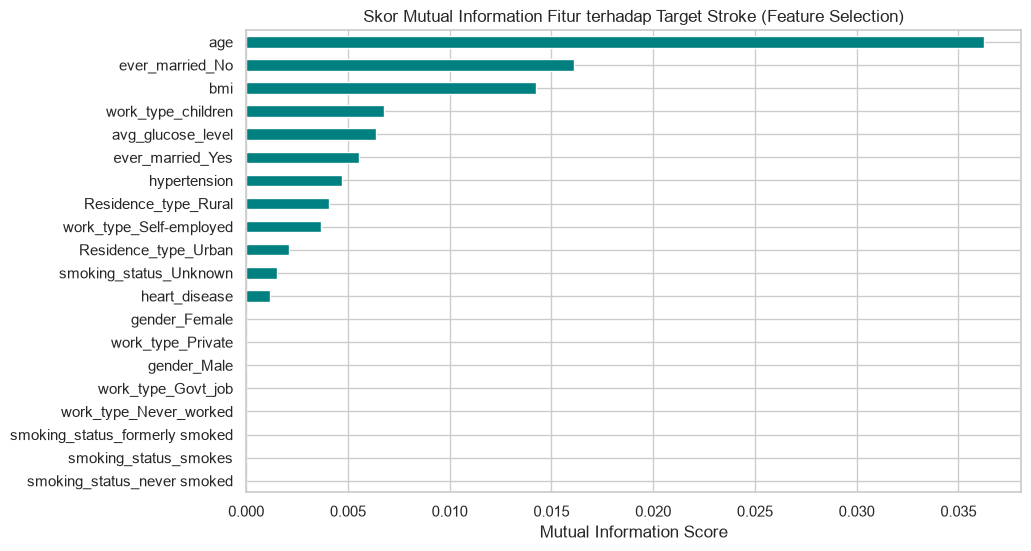


=== Distribusi Kelas Target Data Train (Sebelum vs Sesudah Random Oversampling) ===


,Sebelum Balancing,Sesudah Random Oversampling
stroke,,
0,3888,3888
1,199,3888


,age,avg_glucose_level,bmi,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,hypertension,heart_disease
0,1.269492,-1.088283,-0.639911,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-1.734111,-0.568934,-1.441292,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
2,-1.822453,0.082042,-1.609323,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.960298,-0.110028,-0.084115,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.165226,0.097488,1.996889,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


In [5]:
# 1. Pemisahan Fitur (X) dan Target (y) dari df_clean
X = df_clean.drop(columns=['stroke'])
y = df_clean['stroke']

# 2. Train-Test Split (80:20) dengan Stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Definisi Pipeline Preprocessing
num_cols = ['age', 'avg_glucose_level', 'bmi']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
binary_cols = ['hypertension', 'heart_disease']

num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols),
    ('passthrough', 'passthrough', binary_cols)
])

# Fit pada train, transform pada train & test
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

# Konversi kembali ke DataFrame dengan nama kolom lengkap
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(cat_cols))
all_feature_names = num_cols + encoded_cat_cols + binary_cols

X_train_df = pd.DataFrame(X_train_prepared, columns=all_feature_names)
X_test_df = pd.DataFrame(X_test_prepared, columns=all_feature_names)

print(f"Shape X_train setelah encoding & scaling : {X_train_df.shape}")
print(f"Shape X_test setelah encoding & scaling  : {X_test_df.shape}")

# 4. Feature Selection: Evaluasi Kepentingan Fitur dengan Mutual Information
mi_scores = mutual_info_classif(X_train_df, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=X_train_df.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
mi_series.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title('Skor Mutual Information Fitur terhadap Target Stroke (Feature Selection)')
plt.xlabel('Mutual Information Score')
plt.show()

# 5. Penanganan Class Imbalance dengan Random Oversampling (Bawaan Pandas - Hanya pada Data Train)
train_combined = X_train_df.copy()
train_combined['stroke'] = y_train.values

df_majority = train_combined[train_combined['stroke'] == 0]
df_minority = train_combined[train_combined['stroke'] == 1]

# Oversampling kelas minoritas agar seimbang dengan kelas mayoritas
df_minority_upsampled = df_minority.sample(n=len(df_majority), replace=True, random_state=42)
train_balanced = pd.concat([df_majority, df_minority_upsampled]).sample(frac=1, random_state=42).reset_index(drop=True)

X_train_balanced = train_balanced.drop(columns=['stroke'])
y_train_balanced = train_balanced['stroke']

print("\n=== Distribusi Kelas Target Data Train (Sebelum vs Sesudah Random Oversampling) ===")
imbalance_comp = pd.DataFrame({
    'Sebelum Balancing': y_train.value_counts(),
    'Sesudah Random Oversampling': y_train_balanced.value_counts()
})
display(imbalance_comp)
display(X_train_balanced.head())

### 5.2 Keputusan Akhir Feature Selection
* **Fitur Dibuang**: `id` (identifier acak tanpa informasi medis, berisiko menimbulkan *overfitting*).
* **Fitur Dipertahankan (10 Variabel Awal $\rightarrow$ 20 Kolom Hasil One-Hot Encoding)**: Berdasarkan hasil visualisasi *Mutual Information* dan domain medis, fitur utama seperti `age`, `avg_glucose_level`, `hypertension`, `heart_disease`, `ever_married`, dan `bmi` memiliki kontribusi informasi yang jelas terhadap variabel target. Seluruh 20 fitur hasil transformasi dipertahankan untuk tahap pemodelan berikutnya serta dapat dievaluasi lebih lanjut menggunakan *feature importance* berbasis model.

## 6. Visualisasi Tambahan: Audit dan Sebelum vs Sesudah Cleaning
Statistik deskriptif lengkap (termasuk median), missing bmi per kelas, distribusi bmi sebelum/sesudah imputasi median, dan persentase outlier IQR.

                    count    mean    std    min  median     max
age                5110.0   43.23  22.61   0.08   45.00   82.00
avg_glucose_level  5110.0  106.15  45.28  55.12   91.88  271.74
bmi                4909.0   28.89   7.85  10.30   28.10   97.60


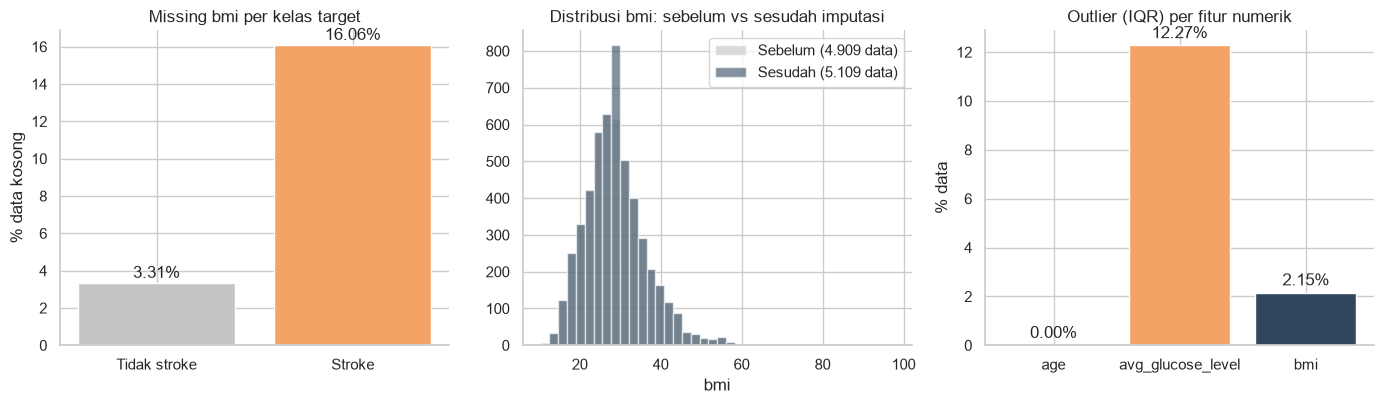

In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
NAVY, ORG, GREY = '#30475E', '#F2A365', '#C4C4C4'

# Statistik deskriptif lengkap (termasuk median)
num = ['age', 'avg_glucose_level', 'bmi']
desc = df[num].agg(['count', 'mean', 'std', 'min', 'median', 'max']).T
print(desc.round(2))

# Data bersih (id & gender Other dibuang, bmi diimputasi median)
df_clean = df.drop(columns=['id']); df_clean = df_clean[df_clean['gender'] != 'Other']
bmi_after = df_clean['bmi'].fillna(df_clean['bmi'].median())

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
# (a) Missing bmi per kelas target
miss = df.groupby('stroke')['bmi'].apply(lambda s: s.isnull().mean() * 100)
b = ax[0].bar(['Tidak stroke', 'Stroke'], miss.values, color=[GREY, ORG])
for r, v in zip(b, miss.values): ax[0].text(r.get_x() + r.get_width()/2, v + 0.3, f'{v:.2f}%', ha='center')
ax[0].set_title('Missing bmi per kelas target'); ax[0].set_ylabel('% data kosong')
# (b) Distribusi bmi sebelum vs sesudah imputasi median
ax[1].hist(df['bmi'].dropna(), bins=40, alpha=.6, color=GREY, label='Sebelum (4.909 data)')
ax[1].hist(bmi_after, bins=40, alpha=.6, color=NAVY, label='Sesudah (5.109 data)')
ax[1].set_title('Distribusi bmi: sebelum vs sesudah imputasi'); ax[1].set_xlabel('bmi'); ax[1].legend()
# (c) Persentase outlier IQR per fitur numerik
pct = []
for c in num:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    pct.append(((df[c] < q1 - 1.5*i) | (df[c] > q3 + 1.5*i)).mean() * 100)
b = ax[2].bar(['age', 'avg_glucose_level', 'bmi'], pct, color=[GREY, ORG, NAVY])
for r, v in zip(b, pct): ax[2].text(r.get_x() + r.get_width()/2, v + 0.3, f'{v:.2f}%', ha='center')
ax[2].set_title('Outlier (IQR) per fitur numerik'); ax[2].set_ylabel('% data')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()


## 7. Pemilihan Model (Progress 3)

Tujuan proyek (Business Understanding) adalah **klasifikasi biner** risiko stroke dengan **Recall** sebagai metrik utama, karena *False Negative* (pasien berisiko yang lolos) lebih berbahaya daripada *False Positive*. Karena itu dipilih empat model klasifikasi dari materi praktikum, dengan peran yang berbeda:

| Model | Peran | Alasan cocok dengan data & tujuan |
| :--- | :--- | :--- |
| **Logistic Regression** | *Baseline* | Sederhana, cepat, koefisiennya mudah dijelaskan ke tenaga medis, dan menghasilkan probabilitas risiko. Fitur sudah di-*scale* sehingga cocok untuk model linear. |
| **K-Nearest Neighbors (KNN)** | Pembanding berbasis jarak | Tidak berasumsi bentuk hubungan fitur-target. Fitur sudah distandardisasi sehingga perhitungan jarak adil. Dipakai untuk melihat apakah pasien stroke "mengelompok" di ruang fitur. |
| **Decision Tree** | Model yang dapat dibaca | Menghasilkan aturan *if-then* (mis. usia > x dan hipertensi) yang sesuai dengan temuan EDA bahwa usia dan penyakit penyerta adalah faktor dominan. Tidak sensitif terhadap *outlier* glukosa yang sengaja dipertahankan. |
| **Random Forest** | Model *ensemble* | Gabungan banyak pohon untuk menurunkan *overfitting* tunggal pohon dan menangkap interaksi antar fitur (usia x glukosa x BMI). |

Dengan empat model ini, sekaligus bisa dibandingkan model sederhana vs kompleks pada data yang kecil dan sangat timpang (249 kasus stroke).

## 8. Proses Training & Pengaturan Parameter

**Prinsip yang dipakai:**
1. **`random_state=42`** ditetapkan di semua tempat yang mengandung unsur acak (split, oversampling, CV, model) sehingga hasil identik saat notebook dijalankan ulang.
2. Parameter dipilih lewat **Stratified 5-Fold Cross Validation pada data train saja**. Data test tidak disentuh sampai evaluasi akhir.
3. Agar **tidak terjadi data leakage**, di dalam setiap fold: preprocessing di-*fit* hanya pada bagian *train* fold, lalu *random oversampling* hanya dilakukan pada bagian *train* fold. Bagian validasi fold tetap berdistribusi asli (~4,9% stroke).
4. **Kriteria memilih parameter: skor F2** (Recall dibobotkan 4x lebih penting dari Precision). Memakai Recall murni akan selalu memilih model yang menebak semua pasien "stroke" (Recall 100% tetapi tidak berguna), sedangkan F2 tetap mengutamakan Recall sesuai tujuan bisnis namun menghukum model yang terlalu banyak alarm palsu.

In [7]:
# Blok 1: import model & metrik, serta fungsi bantu.
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

RANDOM_STATE = 42

def build_preprocessor():
    # Salinan pipeline preprocessing yang sama dengan Progress 2 (belum di-fit)
    return ColumnTransformer(transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
        ('passthrough', 'passthrough', binary_cols)
    ])

def random_oversample(X_arr, y_arr, seed=RANDOM_STATE):
    # Random oversampling kelas minoritas (tanpa data sintetis), sama dengan metode Progress 2
    rng = np.random.RandomState(seed)
    idx_maj, idx_min = np.where(y_arr == 0)[0], np.where(y_arr == 1)[0]
    idx_min_up = rng.choice(idx_min, size=len(idx_maj), replace=True)
    idx = np.concatenate([idx_maj, idx_min_up]); rng.shuffle(idx)
    return X_arr[idx], y_arr[idx]

In [8]:
# Blok 2: fungsi Cross Validation tanpa kebocoran data.
def cv_scores(make_model, params, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rec, prec, f2 = [], [], []
    for tr_idx, va_idx in skf.split(X_train, y_train):
        pre = build_preprocessor()
        A = pre.fit_transform(X_train.iloc[tr_idx])          # fit hanya pada train-fold
        V = pre.transform(X_train.iloc[va_idx])              # validasi hanya di-transform
        A, a = random_oversample(A, y_train.iloc[tr_idx].values)  # oversampling hanya pada train-fold
        pred = make_model(**params).fit(A, a).predict(V)
        yv = y_train.iloc[va_idx]
        rec.append(recall_score(yv, pred)); prec.append(precision_score(yv, pred, zero_division=0))
        f2.append(fbeta_score(yv, pred, beta=2))
    return np.mean(rec), np.mean(prec), np.mean(f2)

In [9]:
# Blok 3: ruang pencarian parameter tiap model.
# Rentang dipilih dari sangat sederhana sampai sangat kompleks agar terlihat titik underfitting-overfitting.
search_space = {
    'Logistic Regression': (lambda **p: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **p),
                            'C', [0.01, 0.1, 1, 10]),                    # C kecil = regularisasi kuat
    'KNN':                 (KNeighborsClassifier,
                            'n_neighbors', [3, 5, 11, 21, 51, 101, 151]), # k kecil = rawan overfitting
    'Decision Tree':       (lambda **p: DecisionTreeClassifier(random_state=RANDOM_STATE, **p),
                            'max_depth', [2, 3, 4, 5, 7, 10, None]),      # None = pohon tumbuh penuh
    'Random Forest':       (lambda **p: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **p),
                            'max_depth', [3, 5, 8, 12, None]),
}

tuning_rows, best_params = [], {}
for name, (maker, pname, values) in search_space.items():
    for v in values:
        rec, prec, f2 = cv_scores(maker, {pname: v})
        tuning_rows.append({'Model': name, 'Parameter': pname, 'Nilai': str(v),
                            'CV Recall': rec, 'CV Precision': prec, 'CV F2': f2})
tuning_df = pd.DataFrame(tuning_rows)

# Parameter terbaik = F2 tertinggi per model
for name in search_space:
    sub = tuning_df[tuning_df['Model'] == name]
    row = sub.loc[sub['CV F2'].idxmax()]
    pname = search_space[name][1]
    best_params[name] = {pname: (None if row['Nilai'] == 'None' else int(row['Nilai']) if pname != 'C' else float(row['Nilai']))}

display(tuning_df.round(3))
print("Parameter terbaik hasil Cross Validation:", best_params)

,Model,Parameter,Nilai,CV Recall,CV Precision,CV F2
0,Logistic Regression,C,0.01,0.809,0.134,0.402
1,Logistic Regression,C,0.1,0.809,0.137,0.408
2,Logistic Regression,C,1,0.809,0.137,0.408
3,Logistic Regression,C,10,0.804,0.136,0.406
4,KNN,n_neighbors,3,0.166,0.091,0.142
5,KNN,n_neighbors,5,0.241,0.095,0.185
6,KNN,n_neighbors,11,0.472,0.106,0.279
7,KNN,n_neighbors,21,0.668,0.105,0.322
8,KNN,n_neighbors,51,0.744,0.110,0.346
9,KNN,n_neighbors,101,0.824,0.119,0.377


Parameter terbaik hasil Cross Validation: {'Logistic Regression': {'C': 1.0}, 'KNN': {'n_neighbors': 101}, 'Decision Tree': {'max_depth': 3}, 'Random Forest': {'max_depth': 5}}


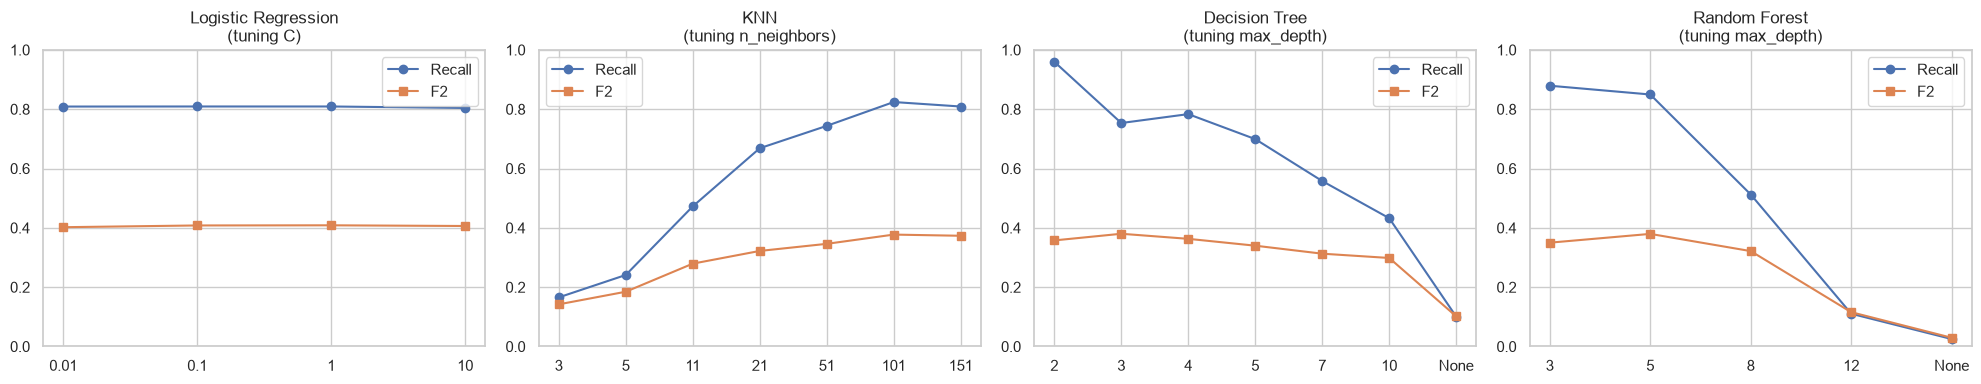

In [10]:
# Blok 4: visualisasi pengaruh parameter terhadap Recall dan F2 (bukti parameter tidak dipilih asal).
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, name in zip(axes, search_space):
    sub = tuning_df[tuning_df['Model'] == name].reset_index(drop=True)
    ax.plot(sub['Nilai'], sub['CV Recall'], marker='o', label='Recall')
    ax.plot(sub['Nilai'], sub['CV F2'], marker='s', label='F2')
    ax.set_title(f"{name}\n(tuning {sub['Parameter'][0]})"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.show()

**Cara membaca hasil tuning:**
* **Decision Tree & Random Forest**: Recall tertinggi muncul pada `max_depth` sangat kecil (pohon hampir menebak "stroke" untuk banyak pasien), tetapi Precision sangat rendah. Sebaliknya, pohon yang dibiarkan tumbuh penuh (`None`) **menghafal** data oversampling (banyak salinan pasien stroke yang sama) sehingga Recall pada data validasi jatuh mendekati 0. Kedalaman dipilih dari **F2 tertinggi**, yaitu titik tengah yang menyeimbangkan keduanya.
* **KNN**: nilai k kecil buruk karena salinan duplikat hasil oversampling menjadi tetangga terdekat sehingga model *overfitting*. F2 naik seiring k membesar (prediksi lebih halus) lalu mendatar pada k=101 dan 151, sehingga k=101 dipilih.
* **Logistic Regression**: hampir tidak sensitif terhadap `C` sehingga model ini stabil.

## 9. Training Model Final & Hasil Modelling

Setiap model dilatih ulang dengan parameter terbaik pada **seluruh data train hasil Progress 2** (`X_train_balanced`, `y_train_balanced`), lalu diuji sekali pada **data test** (`X_test_df`) yang belum pernah dilihat model.

In [11]:
# Blok 5: training final tiap model memakai data train hasil Progress 2 + prediksi pada data test.
final_models, results, preds = {}, [], {}
for name, (maker, pname, _) in search_space.items():
    model = maker(**best_params[name])
    model.fit(X_train_balanced, y_train_balanced)          # data train hasil Progress 2 (sudah seimbang)
    y_pred = model.predict(X_test_df)                       # prediksi kelas
    y_prob = model.predict_proba(X_test_df)[:, 1]           # probabilitas stroke
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    final_models[name], preds[name] = model, (y_pred, y_prob)
    results.append({'Model': name, 'Parameter': str(best_params[name]),
                    'Recall': recall_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred),
                    'F1': f1_score(y_test, y_pred), 'F2': fbeta_score(y_test, y_pred, beta=2),
                    'ROC-AUC': roc_auc_score(y_test, y_prob), 'PR-AUC': average_precision_score(y_test, y_prob),
                    'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn})
results_df = pd.DataFrame(results).set_index('Model')
print("=== Tabel Perbandingan Model pada Data Test ===")
display(results_df.round(3))

=== Tabel Perbandingan Model pada Data Test ===


,Parameter,Recall,Precision,F1,F2,ROC-AUC,PR-AUC,TP,FN,FP,TN
Model,,,,,,,,,,,
Logistic Regression,{'C': 1.0},0.80,0.134,0.229,0.401,0.838,0.267,40,10,259,713
KNN,{'n_neighbors': 101},0.80,0.119,0.207,0.372,0.815,0.191,40,10,297,675
Decision Tree,{'max_depth': 3},0.84,0.105,0.186,0.349,0.821,0.183,42,8,359,613
Random Forest,{'max_depth': 5},0.82,0.110,0.193,0.357,0.822,0.238,41,9,333,639


Model dengan F2 tertinggi: Logistic Regression


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke_aktual,prob_stroke,prediksi
220,Male,81.0,1,1,Yes,Private,Urban,250.89,28.1,smokes,1,0.970,1
187,Female,82.0,1,1,Yes,Govt_job,Urban,215.94,27.9,formerly smoked,1,0.967,1
215,Female,79.0,0,1,No,Private,Urban,205.33,31.0,smokes,1,0.947,1
894,Male,81.0,1,0,Yes,Self-employed,Urban,231.19,31.6,formerly smoked,0,0.945,1
3317,Male,81.0,1,1,No,Private,Rural,220.64,30.0,never smoked,0,0.943,1
3685,Female,80.0,1,0,Yes,Self-employed,Urban,218.00,33.5,Unknown,0,0.937,1
76,Male,80.0,1,0,Yes,Private,Urban,240.09,27.0,never smoked,1,0.932,1
2979,Female,82.0,1,0,Yes,Self-employed,Urban,107.21,27.0,formerly smoked,0,0.926,1
2453,Male,82.0,0,0,Yes,Private,Urban,214.42,33.9,formerly smoked,0,0.926,1
1776,Female,78.0,1,0,Yes,Private,Rural,91.63,33.5,smokes,0,0.925,1


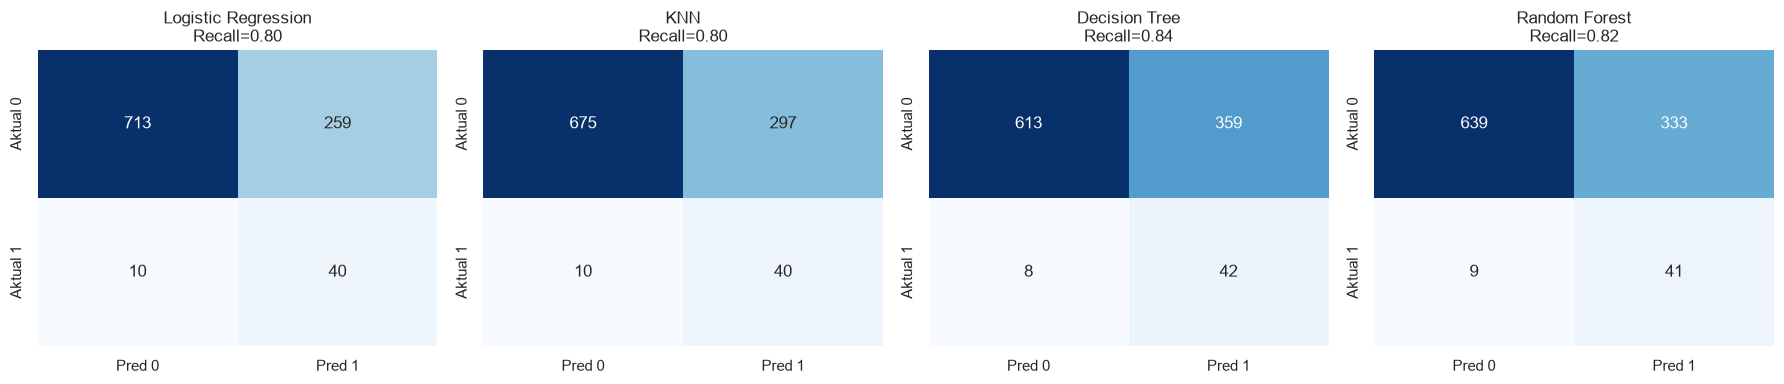

In [12]:
# Blok 6: contoh hasil prediksi awal (10 pasien data test dengan probabilitas stroke tertinggi menurut model terbaik).
best_model_name = results_df['F2'].idxmax()
y_pred_b, y_prob_b = preds[best_model_name]
pred_table = X_test.copy()
pred_table['stroke_aktual'] = y_test.values
pred_table['prob_stroke'] = y_prob_b.round(3)
pred_table['prediksi'] = y_pred_b
print(f"Model dengan F2 tertinggi: {best_model_name}")
display(pred_table.sort_values('prob_stroke', ascending=False).head(10))

# Blok 7: confusion matrix keempat model.
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, final_models):
    cm = confusion_matrix(y_test, preds[name][0])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Aktual 0', 'Aktual 1'])
    ax.set_title(f"{name}\nRecall={recall_score(y_test, preds[name][0]):.2f}")
plt.tight_layout(); plt.show()

## 10. Interpretasi Hasil Awal

* **Keempat model menangkap 80% sampai 84% pasien stroke di data test** (40 sampai 42 dari 50 kasus), jauh lebih baik dibanding model naif yang selalu menebak "tidak stroke" (Recall 0). Tujuan bisnis (menekan *False Negative*) tercapai pada tahap awal ini.
* **Perbedaan Recall antar model kecil** (hanya selisih 1 sampai 2 pasien dari 50 kasus), sehingga belum bisa disimpulkan satu model lebih unggul hanya dari Recall. Pembeda yang lebih jelas ada pada Precision, F2, ROC-AUC, dan PR-AUC.
* **Logistic Regression** memberi keseimbangan terbaik: F2, Precision, ROC-AUC, dan PR-AUC tertinggi dengan alarm palsu paling sedikit (259 FP). **Decision Tree** punya Recall tertinggi (0,84) tetapi dengan alarm palsu terbanyak (359 FP). **KNN** Recall-nya setara Logistic Regression namun Precision dan PR-AUC lebih rendah. **Random Forest** belum menunjukkan keunggulan dibanding model sederhana pada data sekecil dan setimpang ini.
* **Harga yang dibayar adalah Precision rendah (sekitar 0,10 sampai 0,13)**: dari setiap 10 pasien yang ditandai berisiko, hanya sekitar 1 yang benar-benar stroke. Untuk *screening* awal hal ini masih dapat diterima karena pasien yang ditandai akan menjalani pemeriksaan lanjutan, tetapi menjadi catatan penting.
* Ini adalah **hasil awal**. Data test hanya berisi 50 kasus stroke, sehingga angka masih bisa bergeser. Langkah lanjutan: penyesuaian *threshold*, perbandingan dengan `class_weight='balanced'` tanpa oversampling, dan validasi ulang dengan *repeated CV*.